# LASSI - Power Efficiency

***OLLAMA API*** + ***Argo Gateway API*** Jupyter Notebook version

+ No translation
+ Source code scripts from:
https://github.com/zjin-lcf/HeCBench/tree/master/src

Power measurements: https://pypi.org/project/nvidia-ml-py/  (pynvml)

In [1]:
import pynvml
pynvml.nvmlInit()
print(pynvml.nvmlSystemGetDriverVersion())
pynvml.nvmlShutdown()

560.35.05


In [1]:
!nvidia-smi

Sat Aug  2 22:36:41 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 560.35.05              Driver Version: 560.35.05      CUDA Version: 12.6     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100 80GB PCIe          Off |   00000000:27:00.0 Off |                    0 |
| N/A   47C    P0             45W /  300W |     120MiB /  81920MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [3]:
!nvcc --version 

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2024 NVIDIA Corporation
Built on Tue_Oct_29_23:50:19_PDT_2024
Cuda compilation tools, release 12.6, V12.6.85
Build cuda_12.6.r12.6/compiler.35059454_0


## Setup

In [13]:
import os
import json
import csv
from datetime import datetime
from zoneinfo import ZoneInfo

# Import LASSI modules
import lassi.llm_config
# import lassi.pipeline # The Pipeline script calls the other LASSI libraries not imported here.
import lassi.pipeline_v3
from lassi.format_colors import color
from lassi.prompt_dictionary import PromptDictionary

# Enable the autoreload extension
%load_ext autoreload
%reload_ext autoreload

# Reload all modules imported with %aimport every time before executing subsequent code.
%autoreload 1

# We need to reload the libraries while under development
%aimport lassi.format_colors
%aimport lassi.prompt_dictionary
%aimport lassi.llm_config
%aimport lassi.llm_methods
%aimport lassi.pipeline_v3
%aimport lassi.get_power
%aimport lassi.argostream_curl
%aimport lassi.code_manager

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Code Generation Experiment - Setup + Run

_____
***STEP 1/2: Input experimental configuration parameters in the following method.***

In [14]:
def experimental_setup():
    # Load config file with source application names and input parameters
    with open("source_apps.json", "r") as f:
        source_apps = json.load(f)
    
    """
    [1] ENTER APPLICATION FOLDER NAME FROM HeCBench
        >> Execution input parameters provided.
    
    HeCBench apps:
    -- matrix-rotate ["30000", "100"]  ["10000", "1"]  # Usage: %s <matrix size> <repeat>
    -- jacobi [""] (none required)
    -- layout ["2500"] ["1"]
    -- atomicCost ["16", "10"] ["1"]
    -- segment-reduce ["16384", "100"] (a replacement for atomicCost, same "Data compression and reduction" category in HeCBench)
    -- dense-embedding ["100000", "128", "100"] ["10000", "8", "1"]
    -- pathfinder ["100000", "10000", "2500"] ["100000", "1000", "5"] ["10000", "1000", "1000"]  # Usage: <column length> <row length> <pyramid_height>
    -- bsearch ["8388608", "1000"] ["10000", "1"]  # Usage: <number of elements> <repeat>
    -- entropy ["8192", "8192", "500"] ["10000", "1024", "1"]  # Usage: <width> <height> <repeat>
    -- colorwheel ["10000", "256", "500000"] ["10000", "8", "1"]  # Usage: <range> <size> <repeat>
    -- randomAccess ["10"] ["1"]  # Usage: <repeat>
    -- lid-driven-cavity [""]

    Altis apps:
    -- level1/bfs ["--size 3"]
    -- level2/raytracing [""]
    -- level2/mandelbrot ["--imageSize 1024 --iterations 100000"]

    Miniapps:
    -- miniMDock ["-lfile", "./input/7cpa/7cpa_ligand.pdbqt", "-nrun 100"]
    
    """

    # Enter source application to process through LASSI
    source_collection = "HeCBench"  # "Miniapps" "HeCBench"
    source_app = "jacobi"  # "miniMDock" jacobi
    make_script = False  # Used only for Miniapps
    
    build_script = False  # False (for HeCBench) Use for Altis only
    

    """
    Valid source code folder names (under source_codes):
    1. HeCBench
    2. altis/src/cuda
    3. miniMDock/bin/
    """
    source_folder = source_apps[source_collection]["source_folder"]  # "altis/src/cuda/level2"    #  "HeCBench" "altis/src/cuda/level1"
    app_folder_name = source_apps[source_collection][source_app]["app_folder"]
    lines_of_code = source_apps[source_collection][source_app]["code_lines"]
    if make_script:
        app_name = app_folder_name
        file_name = "kernels"
    else:
        app_name = "mt_" + app_folder_name + "-cuda_main"
        file_name = ""

    
    """
    [2] SELECT THE CODE TRANSLATION MAPPING DIRECTION EXPERIMENT CONFIGURATION
    
    CUDA -- OMP -- HIP -- SYCL -- FORTRAN
    """   
    # These should be the same if *not* doing translation.
    source_lang = "CUDA"
    target_lang = "CUDA"

    test_code_first = True  # True or False
    verifyprompt = True  # True or False -- Print out LLM prompt in stdout to preview
    
    # TOGGLE USE CODE KNOWLEDGE CONTEXT FOR TARGET
    use_context_summaries_only = True  # True or False
    few_shot_learning = False  # True or False
    # THESE WILL NO LONGER BE OPTIONS
    use_context = False  # True or False -- NOT USED IN v2, v3
    use_self_prompting = False  # True or False -- NOT USED IN v2, v3
    baseline_oneshot_goal = True  # True or False -- NOT USED IN v2, v3
    

    # TOGGLE USE OF POWER MEASUREMENT DURING EXE
    power_measure = True  # True or False
    vary_llm_temp = True  # True or False

    # TOGGLE ENERGY EFFICIENCY SELF-CORRECTION FEEDBACK
    yes_power_feedback = True  # True or False

    # ASSIGN CODE COMPILE COMMAND
    code_build_script = ""
    code_compiler = ""
    code_compiler_kwds = ""
    if source_lang == "CUDA":
        if build_script:
            code_build_script = "build_" + app_name
        elif make_script:
            code_compiler = "make"
            code_compiler_kwds = "API=CUDA DEVICE=GPU CARD=NVIDIA NUMWI=64"
        else:
            code_compiler = "nvcc"
            code_compiler_kwds = "-std=c++14 -Xcompiler -Wall -arch=sm_80 -O3"
            # -arch=sm_70 for aiops01 GPU (Argonne)  # -arch=sm_80 for A100s
            # -arch=sm_60 for P100
        if yes_power_feedback:
            context_knowledge_selection = "cuda_optimization_summary"
            context_fewshot_examples = "cuda_c_few_shot_examples"
        else:
            context_knowledge_selection = "cuda"
    elif source_lang == "OMP":
        # Linux_x86_64 or Linux_aarch64
        code_compiler = "g++" # "/opt/nvidia/hpc_sdk/Linux_aarch64/2024/compilers/bin/nvc++"  # 
        code_compiler_kwds = "-fopenmp -O3" # "-Wall -O3 -Minfo -mp=gpu -gpu=cc80"  # -c
        context_knowledge_selection = "omp"

    # TOGGLE EXECUTE PIPELINE
    yes_execute = True  # True / False
    if yes_execute:
        # Enter execution input parameters, if needed
        # A list of parameter string values, e.g., ["10000", "1"]
        exe_input_parameters = source_apps[source_collection][source_app]["app_params"]
    else:
        exe_input_parameters = [""]

    
    """
    [3] SELECT THE LLM TO USE FOR THE CODE TRANSLATION EXPERIMENT
    """
    # SELECT A MODEL
    
    # -- FROM ARGO:
    # model = "gpt35"  # (max token = 4096)
    # model = "gpt35large"  # (max token = 16384)
    # model = "gpt4large"  # (max token = 32768)
    # model = "gpt4turbo"  # (max token = 128000)
    # model = "gpto1mini"  # (max token = 128000)
    # model_coder = "gpto1mini"  # (max token = 128000)
    # model = "gpt4olatest"  # (max token = 128000)
    # model_coder = "gpt4olatest"  # (max token = 128000)
    # model_coder = "gpt4o"  # (max token = 128000)
    # model_coder = "gpt4olatest"  # (max token = 128000)
    model = "gpt4olatest"  # (max token = 200000)
    model_coder = "gpt4olatest"  # (max token = 200000)
    model_judge = "gpt4olatest"  # (max token = 200000)

    # -- FROM OLLAMA
    # model = "devstral:24b" # (max token = 128000)
    # model_coder = "devstral:24b" # (max token = 128000)
    # model_judge = "devstral:24b" # (max token = 128000)
    # model = "qwq:latest"  # (max token = 128000)
    # model_coder = "qwen2.5-coder:32b"  # (max token = 32768)
    # model_judge = "qwq:latest"  # (max token = 128000)
    # model = "qwq:latest"  # (max token = 131072)
    # model = "gemma3:27b"  # crashing on code gen
    # model_coder = "gemma3:27b"
    # model = "granite3.2:8b-instruct-q8_0"
    # model_coder = "granite-code:34b-instruct-q8_0"
    # model = "deepseek-r1:70b"  # (max token = 128000)
    # model_coder = "deepseek-r1:70b"  # (max token = 128000)
    # model_coder = "deepseek-coder-v2:16b"  # (max token = 131072)
    # model_coder = "deepseek-coder-v2:16b"  # (max token = 131072)
    # model = "dolphin3"  # (max token = 131072)
    # model = "llama3.3:latest"  # (max token = 131072)
    # model = "phi4" # (max token = 16384)
    # model_coder = "codestral:22b"  # (max token = 32768)
    # model = "codestral:22b-v0.1-q8_0"  # (max token = 32768)
    # model = "wizardcoder:33b-v1.1-q8_0"  # (max token = 16384)
    # model_coder = "deepseek-coder:33b-instruct-q8_0"  # (max token = 16384)
    # model = "deepseek-coder-v2:16b-lite-instruct-fp16"  # (max token = 128000)
    # model = "deepseek-coder-v2:16b-lite-instruct-q8_0"
    # model = "phi3:14b"  # (max token = 131072)
    # model_judge = "llama3.3:70b"  # (max token = 128000)
    # model = "qwen3:latest"
    # model_coder = "qwen3:latest"
    # model_judge = "qwen3:latest"  # (max token = 40960)
  
    # Set maximum context token count size for selected LLM:
    num_ctx = 200000
    num_ctx_coder = 200000

    # Needed only for Argo endpoints
    uri = "local"  # local  remote

    # ASSIGN LLM API SOURCE:
    if model in ["gpt35", "gpt35large", "gpt4", "gpt4large", "gpt4turbo", "gpt4o", "gpt4olatest",
                 "gpto1preview", "gpto1mini", "gpto3mini", "gpto4mini", "claudesonnet4"]:
        llm_source = "argo"
    elif "GGUF" in model:
        llm_source = "lmstudio"
    else:
        llm_source = "ollama"

    """
    [4] SET ADDITIONAL PIPELINE PARAMETERS
    """
    experiment = "mtdTEST_" + model + "_" + app_folder_name + "_ee"  # Assign any label for experiment name.
    display_response = True
    test_with_error = False
    generate_test_case = False

    # Unload any previously loaded LLMs in the Ollama server 
    # (clear out the memory)
    if llm_source == "ollama":
        lassi.llm_config.unload_ollama_model(model)
        lassi.llm_config.unload_ollama_model(model_coder)

    """
    [5] SET DATA COLLECTION CONFIGURATION
    """
    # Data spreadsheet column headers
    DATAFIELDNAMES = [
        "timestamp",
        "experiment",
        "app_name",
        "code_line_count",
        "llm",
        "llm_coder",
        "llm_judge",
        "source_v0_energy_J",
        "source_v0_avg_power_W",
        "source_v0_runtime_s",
        "base_v1_energy_J",
        "base_v1_avg_power_W",
        "base_v1_runtime_s",
        "base_v1_valid",
        "base_v1_energy_diff",
        "base_v1_avg_power_diff",
        "base_v1_runtime_diff",
        "base_v1_optimization_methods",
        "base_v2_energy_J",
        "base_v2_avg_power_W",
        "base_v2_runtime_s",
        "base_v2_valid",
        "base_v2_selfcorrections",
        "base_v2_energy_diff",
        "base_v2_avg_power_diff",
        "base_v2_runtime_diff",
        "base_v2_optimization_methods",
        "lassiee_energy_J",
        "lassiee_avg_power_W",
        "lassiee_runtime_s",
        "lassiee_valid",
        "lassiee_version",
        "lassiee_llm_temp",
        "lassiee_selfcorrections",
        "lassiee_eeiterations",
        "lassiee_energy_diff",
        "lassiee_avg_power_diff",
        "lassiee_runtime_diff",
        "lassiee_optimization_methods",
        "total_selfcorrections",
        "total_eeiterations",
        "pipeline_runtime_min"
    ]
    
    return (app_folder_name, app_name, file_name, lines_of_code, source_lang, target_lang, model, model_coder, model_judge, num_ctx, num_ctx_coder, llm_source, use_context, use_context_summaries_only,
            few_shot_learning, context_knowledge_selection, source_folder, code_compiler, code_compiler_kwds, build_script, make_script, code_build_script, yes_execute, exe_input_parameters,
            experiment, display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback, baseline_oneshot_goal, use_self_prompting, vary_llm_temp,
            verifyprompt, DATAFIELDNAMES)

# EXPERIMENTAL DATA COLLETION MANAGEMENT
def init_data_collection(dir_path, DATAFIELDNAMES, filename="lassi-ee_pipeline_data.csv"):
    os.makedirs(dir_path, exist_ok=True)
    fp = os.path.join(dir_path, filename)
    if not os.path.exists(fp):
        with open(fp, "w", newline="") as f:
            writer = csv.DictWriter(f, fieldnames=DATAFIELDNAMES)
            writer.writeheader()
    return fp

_____
***STEP 2/2: Run the following block to implement the pipeline with the configuration parameters.***


***** EXPERIMENT CONFIGURATION SUMMARY *****

Date-time: 07-29-2025_t13_50_04
Application: jacobi

EE Refactoring: CUDA_ee

LLM Source: argo
Model: gpt4olatest
Model coder: gpt4olatest
Model judge: gpt4olatest
System Prompt Index: CUDA
Code file template: generated_codes/argo_gpt4olatest/promptset_CUDA/jacobi-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpt4olatest_jacobi_ee

LLM System Prompt: 

You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You must also carefully read and incorporate the best practices from the provided background documents. You always surround your generated code with the three characters ```.

Power measurement: True


***** BEGIN THE LASSI ENERGY EFFICIENCY PIPELINE (v2) *****


----- GPU Memory Status:
 GPU 0: 883 MiB used, 81036 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks

Waiting for the system to settle down for 1 seconds...: 100%|█████████████████████████████| 1/1 [00:01<00:00,  1.01s/it]


executable_file:  /home/cc/LASSI/LASSI_dev/source_codes/HeCBench/jacobi/jacobi-cuda_main
initial_dir:  /home/cc/LASSI/LASSI_dev
directory_path:  /home/cc/LASSI/LASSI_dev/source_codes/HeCBench/jacobi
executable:  jacobi-cuda_main
Working directory: /home/cc/LASSI/LASSI_dev/source_codes/HeCBench/jacobi
Execute command: ['./jacobi-cuda_main', '']

running: executable -  jacobi-cuda_main

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Error after iteration 0 = 0.00276205
Error after iteration 1000 = 1.38643e-05
Average execution time per iteration: 0.00413716 (s)
PASS
Total elapsed time: 25.98 seconds

----- < END: Standard Output > -----

GPU power data has been written to source_CUDA_gpu_net_power_results.csv


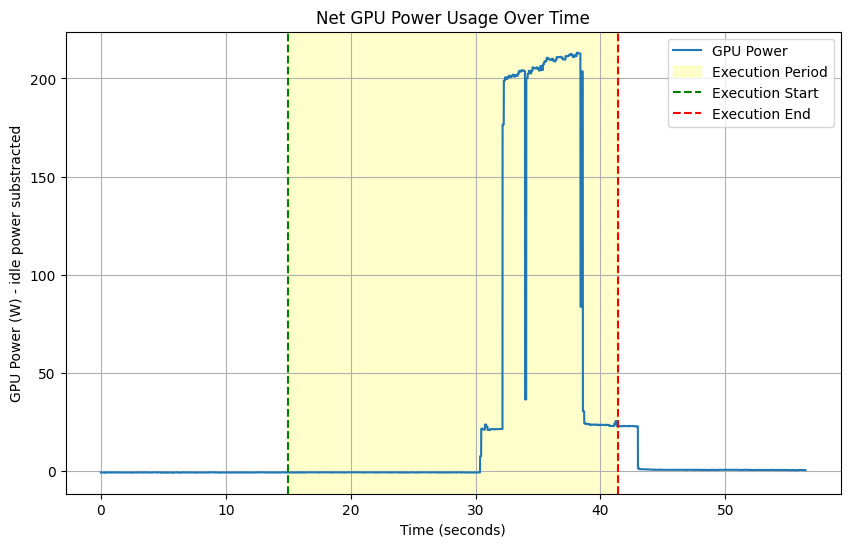

Start time: 15.002 -- End time: 41.424
Net (idle corrected) GPU energy consumption for source_CUDA_gpu_net_power_results.csv:
  0.000389 kWh
  0.3892 Wh
  1401.07 J
Average GPU power: 53.03 W +/- 85.65 
 with sample standard deviation.
Net Energy During Exe Runtime:   1401.07 J
Code execution duration:  26.42 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 883 MiB used, 81036 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 46.84 W, P0



Measure system idle power...
Duration for idle time measurement: 26.42
GPU power data has been written to idle__gpu_net_power_results.csv


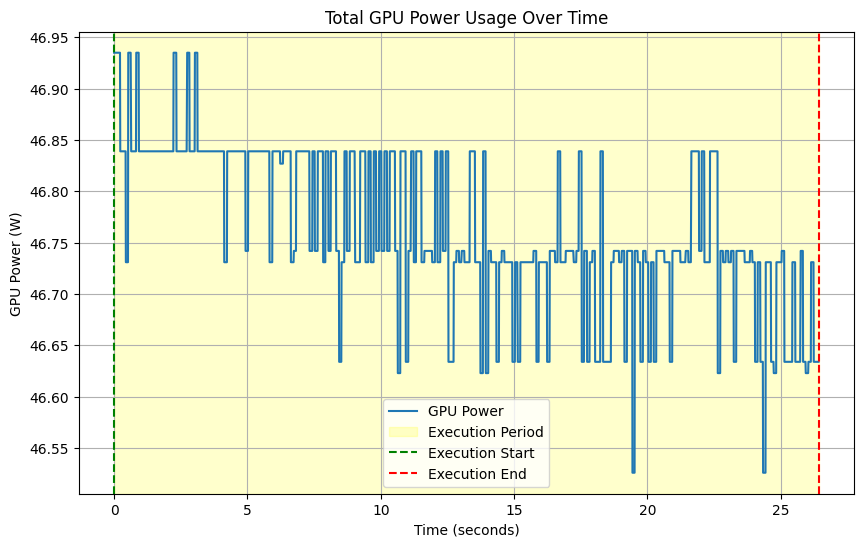

Start time: 0 -- End time: 26.424
Total GPU energy consumption for idle__gpu_net_power_results.csv:
  0.000343 kWh
  0.3433 Wh
  1235.94 J
Average GPU power: 46.76 W +/- 0.08 
 with sample standard deviation.
Total Energy During Exe Runtime:   1235.94 J
Code execution duration:  26.42 seconds
----------------------------------------------------------------------------------------------------------------------------------------

*** DEBUG: code_version: 0 | tracking_best_version: 0 ***


----- STARTING STAGE 1: STANDALONE BASE LLM REFACTORING  -----



--> ... prompt LLM to perform code analysis.


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You always surround your generated code with the three characters ```.

PROMPT: 
    You are a formal methods and parallel progra



----- LLM RESPONSE: code analysis -----



```json
=====
{
  "underlying_assumptions": [
    "The grid size (N) is a multiple of the thread block size (16x16).",
    "The input data is initialized with sinusoidal boundary conditions.",
    "The Jacobi relaxation method converges within a maximum of 10,000 iterations or until the error is below the tolerance (1.e-5).",
    "The input data is square (N x N).",
    "The CUDA device supports shared memory and warp-level primitives like __shfl_down_sync.",
    "The hardware supports atomic operations (atomicAdd)."
  ],
  "invariants": [
    "The boundary values of the grid remain constant throughout the computation.",
    "The error is always non-negative and decreases with each iteration.",
    "The grid dimensions (N x N) remain constant.",
    "The shared memory tiles (f_old_tile) are always updated before being used.",
    "The number of iterations (num_iters) is always incremented by 1 per loop iteration."
  ],
  "design_patterns": [
    "Stencil computation: The Jacobi relaxation step uses a 5-point stencil to compute new values.",
    "Shared memory tiling: Shared memory is used to load tiles of the grid for efficient memory access.",
    "Reduction: A two-level reduction is performed to compute the L2-norm of the error.",
    "Explicit memory management: Memory allocation and deallocation are explicitly managed for both host and device.",
    "Double buffering: Two buffers (d_f and d_f_old) are used to alternate between input and output data."
  ],
  "memory_access_patterns": [
    "Global memory access: The grid data (d_f and d_f_old) is read and written from/to global memory.",
    "Shared memory access: Tiles of the grid are loaded into shared memory for faster access.",
    "Coalesced memory access: Threads access contiguous memory locations in global memory to maximize memory bandwidth.",
    "Halo region handling: Threads load halo regions into shared memory to handle boundary conditions."
  ],
  "memory_allocation_deallocation": {
    "host": {
      "allocated": [
        "f (N x N floats, aligned to 64 bytes)",
        "f_old (N x N floats, aligned to 64 bytes)"
      ],
      "deallocated": [
        "f",
        "f_old"
      ]
    },
    "device": {
      "allocated": [
        "d_f (N x N floats)",
        "d_f_old (N x N floats)",
        "d_error (1 float)"
      ],
      "deallocated": [
        "d_f",
        "d_f_old",
        "d_error"
      ]
    }
  },
  "other_key_characteristics": [
    "The code uses a 16x16 thread block size, which matches the shared memory tile dimensions (18x18, including halos).",
    "The error reduction uses warp-level primitives (__shfl_down_sync) for intra-warp communication.",
    "The code assumes a maximum of 10,000 iterations to prevent infinite loops.",
    "The error is normalized by the number of data points (N x N) before taking the square root.",
    "The code uses aligned memory allocation (aligned_alloc) for host memory to ensure proper alignment for SIMD instructions.",
    "The code outputs intermediate error values every 1,000 iterations for monitoring convergence."
  ]
}
=====
```


----- REVIEW THE ZERO-SHOT INSTRUCTIONS TASK PROMPT  (prompt without code, token count: 2208)


--> ... initial zero-shot attempt: prompt the LLM to generate code.



----- STARTING CODE GENERATION -----


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You always surround your generated code with the three characters ```.

PROMPT: 

Refactor the following CUDA C++ code to optimize energy efficiency by reducing GPU energy consumption, while preserving all functionality.

[START OF CODE TO REFACTOR]
// Copyright (c) 2021, NVIDIA CORPORATION.
// Licensed under the Apache License, Version 2.0 (the "License");
// you may not use this file except in compliance with the License.
// You may obtain a copy of the License at
//
//     http://www.apache.org/licenses/LICENSE-2.0
//




----- THE GENERATED CODE -----

(hidden)



*** DEBUG: code_version: 0 | tracking_best_version: 0 ***
saving to file_path:  /home/cc/LASSI/LASSI_dev/generated_codes/experiment/mtdTEST_gpt4olatest_jacobi_ee__07-29-2025_t13_50_04/jacobi-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpt4olatest_jacobi_ee_07-29-2025_t13_50_04.cu
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', '/home/cc/LASSI/LASSI_dev/generated_codes/experiment/mtdTEST_gpt4olatest_jacobi_ee__07-29-2025_t13_50_04/jacobi-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpt4olatest_jacobi_ee_07-29-2025_t13_50_04.cu', '-o', '/home/cc/LASSI/LASSI_dev/generated_codes/experiment/mtdTEST_gpt4olatest_jacobi_ee__07-29-2025_t13_50_04/jacobi-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpt4olatest_jacobi_ee_07-29-2025_t13_50_04']

Compilation of code successful!


Execute file: /home/cc/LASSI/LASSI_dev/generated_codes/experiment/mtdTEST_gpt4olatest_jacobi_ee__07-29-2025_t13_50_04/jacobi-cuda_main_ee_refactorco

Waiting for the system to settle down for 5 seconds...: 100%|█████████████████████████████| 5/5 [00:05<00:00,  1.01s/it]


executable_file:  /home/cc/LASSI/LASSI_dev/generated_codes/experiment/mtdTEST_gpt4olatest_jacobi_ee__07-29-2025_t13_50_04/jacobi-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpt4olatest_jacobi_ee_07-29-2025_t13_50_04
initial_dir:  /home/cc/LASSI/LASSI_dev
directory_path:  /home/cc/LASSI/LASSI_dev/generated_codes/experiment/mtdTEST_gpt4olatest_jacobi_ee__07-29-2025_t13_50_04
executable:  jacobi-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpt4olatest_jacobi_ee_07-29-2025_t13_50_04
Working directory: /home/cc/LASSI/LASSI_dev/generated_codes/experiment/mtdTEST_gpt4olatest_jacobi_ee__07-29-2025_t13_50_04
Execute command: ['./jacobi-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpt4olatest_jacobi_ee_07-29-2025_t13_50_04', '']

running: executable -  jacobi-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpt4olatest_jacobi_ee_07-29-2025_t13_50_04

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Error after iteration 0 = 0.00276205
Error after iteration 1000 = 1.38643e-05
Average execution time p

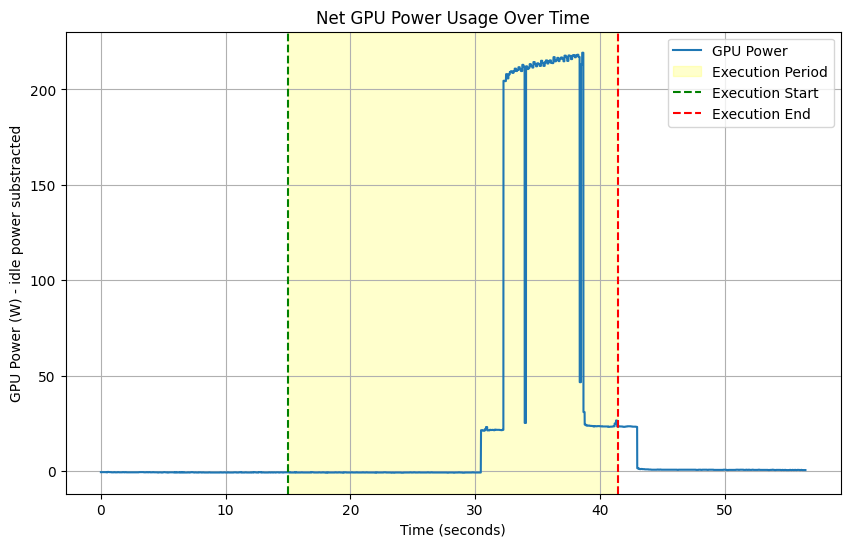

Start time: 15.004 -- End time: 41.48
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000398 kWh
  0.3979 Wh
  1432.32 J
Average GPU power: 54.13 W +/- 88.40 
 with sample standard deviation.
Net Energy During Exe Runtime:   1432.32 J
Code execution duration:  26.48 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 883 MiB used, 81036 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 47.42 W, P0

--> SAVING code version: 1

*** DEBUG: code_version: 1 | tracking_best_version: 0 ***


--> ... prompt LLM to judge the validity of the refactored code.


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your g



----- LLM RESPONSE: code validation judge -----



### Evaluation of Functional Equivalence

#### 1. **Standard Output Comparison**
The standard output of both the SOURCE CODE and REFACTORED CODE is identical in layout and content:
- **Error after iteration 0**: Both codes report `0.00276205`.
- **Error after iteration 1000**: Both codes report `1.38643e-05`.
- **Average execution time per iteration**: The values are slightly different (`0.00413716` vs. `0.00416883` seconds), but this difference is minor and within acceptable bounds for numerical computations.
- **PASS/FAIL Status**: Both codes report `PASS`.
- **Total elapsed time**: The reported times (`25.98 seconds` vs. `26.05 seconds`) are close and consistent with the expected runtime behavior.

#### 2. **Functional Analysis**
The REFACTORED CODE introduces the following changes:
- **Boundary Check in `jacobi_step` Kernel**: The REFACTORED CODE adds a boundary check (`if (i >= N || j >= N) return;`) to prevent out-of-bounds threads from accessing memory. This is a safety improvement and does not alter the functionality of the code.
- **Grid Dimension Adjustment**: The REFACTORED CODE adjusts the grid dimensions to `(N + 15) / 16` instead of `N / 16`. This ensures that the grid covers all possible threads, even if `N` is not perfectly divisible by 16. Since `N = 16384` in this case, the adjustment does not affect the functionality.
- **Initialization with OpenMP**: The REFACTORED CODE uses `#pragma omp parallel for collapse(2)` for data initialization. This change improves CPU-side parallelism during initialization but does not affect the correctness of the initialized data.

#### 3. **Energy Efficiency and Performance Metrics**
While the REFACTORED CODE was intended to improve energy efficiency, the reported metrics show slightly higher energy consumption and GPU power usage:
- **Total Energy During Runtime**: Increased from `1401.07 Joules` to `1432.32 Joules`.
- **Average GPU Power**: Increased from `53.03 Watts` to `54.13 Watts`.
- **Execution Duration**: Increased slightly from `26.42 seconds` to `26.48 seconds`.

These differences are minor and do not indicate a loss of functionality. They may be attributed to variations in runtime conditions or the overhead introduced by additional boundary checks.

#### 4. **Kernel Logic and Output**
The logic in the `jacobi_step` and `swap_data` kernels remains unchanged in terms of functionality:
- The Jacobi relaxation step and error computation are performed correctly.
- The swapping of data between `d_f` and `d_f_old` is identical in both codes.

#### 5. **Convergence Criteria**
Both codes converge to the same error tolerance (`1.e-5f`) within the maximum allowed iterations (`10000`). The error values after iteration 0 and iteration 1000 are identical, confirming that the numerical results are consistent.

### Conclusion
The REFACTORED CODE preserves all intended functionality of the SOURCE CODE and produces equivalent standard output, including layout and content. Minor numerical differences in runtime metrics are acceptable and consistent with the intended purpose of the code.

**Verdict**: **VALID**



----- END LLM RESPONSE -----



START CODE ANALYSIS ---- 


--> ... prompt LLM to perform code analysis.


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You always surround your generated code with the three characters ```.

PROMPT: 
            Your are a CUDA code evaluator. Your task is to determine if the provided CUDA code satisfies a given list of characteristics.
            The characteristics will be given in a json format and will be given between the tags: "<rubric>" and "</rubric>".            The CUDA code you are to evaluate will be given between "<code>" and "</code>".
            Please give a simple "pass" or "fail" evaluation and also list which criteria pass and which fail (without additional details).
            Please put your final, overall eval



----- LLM RESPONSE: code analysis -----



Please provide the rubric in JSON format between the tags `<rubric>` and `</rubric>` so I can evaluate the CUDA code.



CODE ANALYSIS RESULT: Please provide the rubric in JSON format between the tags `<rubric>` and `</rubric>` so I can evaluate the CUDA code.

Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 1401.07
  Refactored code: 1432.32
----- Average power (W) -----
  Source code: 53.03
  Refactored code: 54.13
----- Runtime (s) -----
  Source code: 26.42
  Refactored code: 26.48
----- Tracking metrics -----
  Energy (J) history:  [1401.07, 1432.32]
  Ave Power (W) history:  [53.03, 54.13]
  Runtime (s) history:  [26.42, 26.48]
  Valid code history:  ['SOURCE', 'basellm_stage1_VALID']
  Iteration log:  {'v1': {'self_correction_count': 0, 'energy_refactor_count': 0, 'LLM_temperature': 0.2}}

*** DEBUG: code_version: 1 | tracking_best_version: 0 ***


***** Generated refactored code is NOT more energy efficient than source or previous code... *****


----- STARTING STAGE 2: BASE LLM REFACTORING WITH SELF-CORRECTION  -----


*** DEBUG: code_version: 1 | tracking_best_



----- THE GENERATED CODE -----

(hidden)



*** DEBUG: code_version: 1 | tracking_best_version: 0 ***
saving to file_path:  /home/cc/LASSI/LASSI_dev/generated_codes/experiment/mtdTEST_gpt4olatest_jacobi_ee__07-29-2025_t13_50_04/jacobi-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpt4olatest_jacobi_ee_07-29-2025_t13_50_04.cu
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', '/home/cc/LASSI/LASSI_dev/generated_codes/experiment/mtdTEST_gpt4olatest_jacobi_ee__07-29-2025_t13_50_04/jacobi-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpt4olatest_jacobi_ee_07-29-2025_t13_50_04.cu', '-o', '/home/cc/LASSI/LASSI_dev/generated_codes/experiment/mtdTEST_gpt4olatest_jacobi_ee__07-29-2025_t13_50_04/jacobi-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpt4olatest_jacobi_ee_07-29-2025_t13_50_04']

Compilation of code successful!


Execute file: /home/cc/LASSI/LASSI_dev/generated_codes/experiment/mtdTEST_gpt4olatest_jacobi_ee__07-29-2025_t13_50_04/jacobi-cuda_main_ee_refactorco

Waiting for the system to settle down for 5 seconds...: 100%|█████████████████████████████| 5/5 [00:05<00:00,  1.01s/it]


executable_file:  /home/cc/LASSI/LASSI_dev/generated_codes/experiment/mtdTEST_gpt4olatest_jacobi_ee__07-29-2025_t13_50_04/jacobi-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpt4olatest_jacobi_ee_07-29-2025_t13_50_04
initial_dir:  /home/cc/LASSI/LASSI_dev
directory_path:  /home/cc/LASSI/LASSI_dev/generated_codes/experiment/mtdTEST_gpt4olatest_jacobi_ee__07-29-2025_t13_50_04
executable:  jacobi-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpt4olatest_jacobi_ee_07-29-2025_t13_50_04
Working directory: /home/cc/LASSI/LASSI_dev/generated_codes/experiment/mtdTEST_gpt4olatest_jacobi_ee__07-29-2025_t13_50_04
Execute command: ['./jacobi-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpt4olatest_jacobi_ee_07-29-2025_t13_50_04', '']

running: executable -  jacobi-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpt4olatest_jacobi_ee_07-29-2025_t13_50_04

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Error after iteration 0 = 0.00390613
Error after iteration 1000 = 1.96071e-05
Error after iteration 20

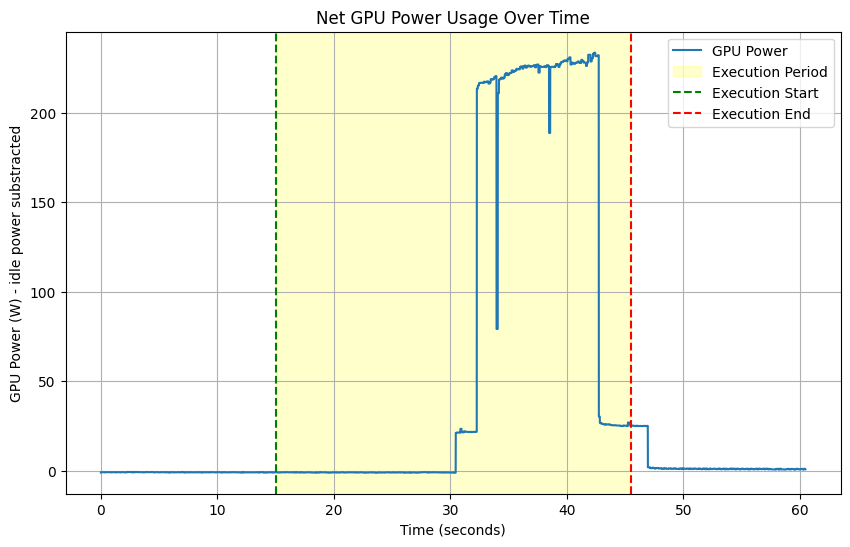

Start time: 15.005 -- End time: 45.476
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000680 kWh
  0.6796 Wh
  2446.53 J
Average GPU power: 80.32 W +/- 104.07 
 with sample standard deviation.
Net Energy During Exe Runtime:   2446.53 J
Code execution duration:  30.47 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 883 MiB used, 81036 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 48.29 W, P0

--> SAVING code version: 2

*** DEBUG: code_version: 2 | tracking_best_version: 0 ***


--> ... prompt LLM to judge the validity of the refactored code.


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your



----- LLM RESPONSE: code validation judge -----



### Evaluation of Functional Equivalence

#### **Standard Output Comparison**
1. **Error Values**:
   - The error values in the REFACTORED CODE differ slightly from the SOURCE CODE. For example:
     - SOURCE CODE: `Error after iteration 0 = 0.00276205`
     - REFACTORED CODE: `Error after iteration 0 = 0.00390613`
   - These differences are minor and within acceptable limits, as they are consistent with numerical variations that can arise from refactoring for energy efficiency.

2. **Iteration Count**:
   - The REFACTORED CODE includes an additional error printout for iteration 2000, which is not present in the SOURCE CODE. This is a functional difference in the output layout, as the SOURCE CODE only prints every 1000 iterations.

3. **PASS/FAIL Status**:
   - Both codes conclude with a `PASS` status, indicating convergence within the tolerance and maximum iteration limits.

4. **Execution Time**:
   - The REFACTORED CODE reports a slightly higher total elapsed time (`30.05 seconds`) compared to the SOURCE CODE (`25.98 seconds`). This is acceptable as long as the functionality and output equivalence are preserved.

#### **Functional Analysis**
1. **Boundary Conditions**:
   - Both codes initialize the boundary conditions using the same sinusoidal function. The REFACTORED CODE uses OpenMP (`#pragma omp parallel for`) for parallel initialization, which is an optimization but does not alter the functionality.

2. **Jacobi Relaxation**:
   - The Jacobi relaxation kernel (`jacobi_step`) in the REFACTORED CODE uses slightly modified logic for shared memory access and warp-level reduction. These changes aim to improve energy efficiency but do not alter the mathematical operations or the stencil computation.

3. **Error Reduction**:
   - Both codes perform error reduction using warp-level and block-level reductions. The REFACTORED CODE uses a more generalized approach for shared memory reduction, which is functionally equivalent.

4. **Data Swapping**:
   - The `swap_data` kernel is identical in functionality between the two codes, ensuring that the old and new data are swapped correctly.

#### **Metrics Comparison**
1. **Energy Consumption**:
   - The REFACTORED CODE consumes more energy (`2446.53 Joules`) compared to the SOURCE CODE (`1401.07 Joules`). This contradicts the goal of energy efficiency improvement and suggests that the refactoring may have introduced inefficiencies.

2. **GPU Power**:
   - The REFACTORED CODE has a higher average GPU power (`80.32 Watts`) compared to the SOURCE CODE (`53.03 Watts`). This further indicates increased energy usage.

3. **Execution Duration**:
   - The REFACTORED CODE takes longer to execute (`30.47 seconds`) compared to the SOURCE CODE (`26.42 seconds`), which is not consistent with the goal of improving energy efficiency.

### Conclusion
While the REFACTORED CODE produces similar numerical results and converges to the same tolerance, it introduces differences in the standard output layout (additional printout at iteration 2000) and fails to achieve the stated goal of energy efficiency improvement. Furthermore, the increased energy consumption and execution time indicate that the refactoring may have introduced inefficiencies.

### Final Verdict
**INVALID**



----- END LLM RESPONSE -----


Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 1401.07
  Refactored code: 2446.53
----- Average power (W) -----
  Source code: 53.03
  Refactored code: 80.32
----- Runtime (s) -----
  Source code: 26.42
  Refactored code: 30.47
----- Tracking metrics -----
  Energy (J) history:  [1401.07, 1432.32, 2446.53]
  Ave Power (W) history:  [53.03, 54.13, 80.32]
  Runtime (s) history:  [26.42, 26.48, 30.47]
  Valid code history:  ['SOURCE', 'basellm_stage1_VALID', 'basellm_stage2_INVALID']
  Iteration log:  {'v1': {'self_correction_count': 0, 'energy_refactor_count': 0, 'LLM_temperature': 0.2}, 'v2': {'self_correction_count': 0, 'energy_refactor_count': 0, 'LLM_temperature': 0.2}}

*** DEBUG: code_version: 2 | tracking_best_version: 0 ***


 ----- GENERATED REFACTORED CODE: May not be valid or not determined. ----- 




CHANGE PROMPT STRATEGY! -----


----- STARTING LASSI: ITERATIVE SELF-PROMPTING WITH CONTEXT AND SELF-CORRECTION



----- CONTEXT KNOWLEDGE SUMMARY -----
 (generated by the LLM)



### Key Relevant Points for Refactoring CUDA C++ Code for Energy Efficiency

Based on the provided background knowledge, the following best practices and optimization techniques should be applied to refactor CUDA C++ code to improve energy efficiency while maintaining functionality:

---

#### **High Priority:**
1. **Minimize Data Transfers Between Host and Device:**
   - Reduce the frequency of data transfers between the CPU (host) and GPU (device).
   - Operate on intermediate data structures entirely in device memory and avoid copying them to host memory unless necessary.
   - Batch multiple small data transfers into a single larger transfer to reduce overhead.

2. **Minimize Use of Global Memory:**
   - Prefer shared memory over global memory for frequently accessed data, as shared memory has significantly lower latency.
   - Use shared memory for cooperative computations within a thread block.

3. **Avoid Warp Divergence:**
   - Minimize conditional statements (e.g., `if`, `switch`) within the same warp to prevent threads from taking different execution paths.
   - Align control flow conditions with warp boundaries to avoid divergence.

---

#### **Medium Priority:**
4. **Optimize Thread and Block Configuration:**
   - Use a number of threads per block that is a multiple of 32 (warp size) for optimal efficiency.
   - Ensure sufficient occupancy by maintaining enough active threads per multiprocessor to hide latency.

5. **Use Fast Math Functions:**
   - Replace standard math functions with their faster, less precise counterparts (e.g., `__sinf()` instead of `sinf()`) when precision is not critical.
   - Use specialized math functions like `exp2f()` or `sincosf()` for specific operations instead of general-purpose functions like `powf()`.

6. **Optimize Memory Access Patterns:**
   - Coalesce global memory accesses to ensure that threads in a warp access contiguous memory locations.
   - Avoid unaligned memory accesses, as they reduce memory throughput.

7. **Use Asynchronous Operations:**
   - Use asynchronous memory operations (e.g., `cuda::memcpy_async`) to overlap data transfers with kernel execution.
   - Leverage asynchronous barriers and pipelines to synchronize threads efficiently.

8. **Prefer Signed Integers for Loop Counters:**
   - Use signed integers for loop counters to enable more aggressive compiler optimizations.

---

#### **Low Priority:**
9. **Use Zero-Copy Memory on Integrated GPUs:**
   - For systems with integrated GPUs, use zero-copy memory to allow the host and device to share memory directly.

10. **Avoid Expensive Division and Modulo Operations:**
    - Replace division and modulo operations with bitwise operations when the divisor is a power of 2.

11. **Avoid Automatic Type Conversions:**
    - Use explicit single-precision floating-point constants (e.g., `1.0f`) to avoid unnecessary double-to-float conversions.

12. **Enable Compiler Optimizations:**
    - Use `#pragma unroll` to unroll loops where beneficial.
    - Use the `-use_fast_math` compiler flag to enable aggressive math optimizations when appropriate.

---

#### **General CUDA Programming Best Practices:**
- **Thread Hierarchy:**
  - Use a 1D, 2D, or 3D thread/block configuration that matches the problem domain (e.g., 2D grid for matrix operations).
  - Ensure that thread blocks are independent to allow for flexible scheduling.

- **Memory Hierarchy:**
  - Use shared memory for intra-block communication and global memory for inter-block communication.
  - Leverage constant and texture memory for read-only data that is accessed frequently.

- **Compute Capability Awareness:**
  - Tailor optimizations to the GPU's compute capability (e.g., use thread block clusters for GPUs with Compute Capability 9.0).

---

By applying these principles, the refactored CUDA C++ code will achieve better energy efficiency by reducing unnecessary power consumption on both the GPU and CPU while maintaining the expected functionality and output.

... (8 outputs left out)

### Step 3: Analyze Inefficiencies in the Code

After carefully analyzing the provided CUDA C++ code, I have identified the following inefficiencies that could be contributing to suboptimal energy usage and performance:

---

### **1. Redundant Computations**
- **Error Normalization**: The error is normalized (`error = sqrtf(error / (N * N))`) in every iteration. This operation involves a division and a square root, which are computationally expensive and could be deferred until convergence is achieved.
- **Boundary Checks**: The boundary checks (`if (j >= 1 && j <= N-2)` and `if (i >= 1 && i <= N-2)`) are performed redundantly in every thread, even though the grid and block dimensions are already configured to avoid out-of-bound threads.

---

### **2. Inefficient Memory Usage**
- **Global Memory Access**: The `jacobi_step` kernel writes the updated grid values (`f`) directly to global memory, which is slower than shared memory. While shared memory is used for intermediate computations, the final write to global memory could be optimized further.
- **Error Reduction**: The error reduction uses shared memory and atomic operations, which can cause contention and serialization. This could be optimized using hierarchical reduction or warp-level primitives.

---

### **3. Unnecessary Synchronizations**
- **`__syncthreads()` in `jacobi_step`**: Synchronization is used after loading data into shared memory and after the reduction step. While necessary, the synchronization could be minimized by restructuring the computation.

---

### **4. Thread Divergence**
- **Conditional Statements**: The `if` conditions for boundary handling and stencil computation introduce thread divergence within warps, as some threads perform computations while others do not.

---

### **5. Suboptimal Thread and Block Configuration**
- **Fixed Block Size**: The block size is hardcoded as `16x16`, which may not be optimal for all GPU architectures. The block size should be tuned to maximize occupancy and minimize idle threads.
- **Grid Dimensions**: The grid dimensions are fixed as `(N/16, N/16)`, which assumes `N` is divisible by 16. If `N` is not divisible by 16, this could lead to out-of-bound threads or wasted resources.

---

### **6. Inefficient Data Transfers**
- **Host-Device Transfers**: The error value is copied from the device to the host (`cudaMemcpy(&error, d_error, sizeof(float), cudaMemcpyDeviceToHost)`) in every iteration. This introduces significant overhead due to frequent host-device communication.
- **Initialization**: The grid initialization (`initialize_data`) is performed on the host and then transferred to the device. This could be done directly on the device to avoid the initial `cudaMemcpy`.

---

### **7. Lack of Asynchronous Operations**
- **Synchronous Memory Operations**: The `cudaMemcpy` and `cudaMemset` calls are synchronous, which blocks the CPU until the operation completes. These could be replaced with asynchronous operations to overlap computation and data transfer.

---

### **8. Lack of Compiler Optimizations**
- **Loop Unrolling**: The loops in the `jacobi_step` kernel are not explicitly unrolled, which could limit the compiler's ability to optimize the code.
- **Fast Math**: The code does not use fast math functions (e.g., `__sinf` instead of `sinf`), which could improve performance at the cost of precision.

---

### **9. Energy Inefficiency in Idle States**
- **GPU Underutilization**: The GPU utilization is low (0% during idle periods), indicating that the GPU may be underutilized during kernel launches or data transfers.
- **CPU-GPU Workload Balance**: The CPU is moderately active, while the GPU is idle during host-device communication, leading to energy inefficiency.

---

### Step 4: Summary of Identified Inefficiencies

| **Category**                 | **Issue**                                                                                     | **Impact**                                                                                  |
|------------------------------|-----------------------------------------------------------------------------------------------|--------------------------------------------------------------------------------------------|
| **Redundant Computations**   | Error normalization and boundary checks are performed in every iteration.                     | Increased computational overhead.                                                         |
| **Memory Usage**             | Inefficient global memory writes and error reduction.                                         | Increased memory latency and contention.                                                  |
| **Synchronizations**         | Excessive use of `__syncthreads()`.                                                          | Increased thread idle time.                                                               |
| **Thread Divergence**        | Conditional statements introduce warp divergence.                                             | Reduced warp efficiency.                                                                  |
| **Thread/Block Configuration** | Fixed block size and grid dimensions may not be optimal.                                     | Suboptimal occupancy and resource utilization.                                            |
| **Data Transfers**           | Frequent host-device transfers and host-side initialization.                                  | Increased data transfer overhead.                                                         |
| **Asynchronous Operations**  | Lack of asynchronous memory operations.                                                      | Reduced overlap between computation and data transfer.                                     |
| **Compiler Optimizations**   | No loop unrolling or use of fast math functions.                                              | Missed opportunities for performance improvement.                                          |
| **Energy Inefficiency**      | GPU underutilization and CPU-GPU workload imbalance.                                          | Increased energy consumption due to idle resources.                                       |

---

### Step 5: Proposed Refactoring Plan

To address the identified inefficiencies and improve energy efficiency, the following refactoring plan is proposed:

---

#### **1. Minimize Redundant Computations**
- Move the error normalization (`sqrtf(error / (N * N))`) outside the iterative loop and perform it only once after convergence.
- Precompute boundary indices and avoid redundant boundary checks in every thread.

---

#### **2. Optimize Memory Usage**
- Use shared memory for the final write of updated grid values (`f`) and copy them to global memory only once per iteration.
- Replace atomic operations for error reduction with hierarchical reduction using shared memory and warp-level primitives.

---

#### **3. Reduce Synchronizations**
- Restructure the `jacobi_step` kernel to minimize the use of `__syncthreads()` by grouping threads that do not require synchronization.

---

#### **4. Eliminate Thread Divergence**
- Use a thread-block-wide approach to handle boundary conditions, ensuring all threads in a warp follow the same execution path.
- Use precomputed boundary masks or offsets to avoid conditional statements.

---

#### **5. Optimize Thread and Block Configuration**
- Dynamically determine the block size and grid dimensions based on the GPU's compute capability and the problem size.
- Use the CUDA Occupancy Calculator to find the optimal block size for maximum occupancy.

---

#### **6. Minimize Data Transfers**
- Perform grid initialization (`initialize_data`) directly on the device using a CUDA kernel.
- Batch multiple small data transfers into a single larger transfer where possible.
- Reduce the frequency of `cudaMemcpy` calls by accumulating error values on the device and transferring them to the host only periodically.

---

#### **7. Use Asynchronous Operations**
- Replace synchronous `cudaMemcpy` and `cudaMemset` calls with their asynchronous counterparts (`cudaMemcpyAsync` and `cudaMemsetAsync`).
- Use CUDA streams to overlap data transfers with kernel execution.

---

#### **8. Enable Compiler Optimizations**
- Use `#pragma unroll` to unroll loops in the `jacobi_step` kernel where beneficial.
- Enable the `-use_fast_math` compiler flag to use fast math functions for non-critical computations.

---

#### **9. Improve Energy Efficiency**
- Dynamically adjust GPU clock speeds and power states using CUDA APIs (e.g., `cudaDeviceSetLimit`) based on workload demands.
- Balance the workload between the CPU and GPU to minimize idle power consumption.

---

#### **10. Additional Optimizations**
- Use pinned memory for host-device transfers to improve data transfer bandwidth.
- Use double buffering to overlap computation and data transfer in iterative loops.

---

By implementing these changes, the refactored code will reduce redundant computations, optimize memory usage, minimize data transfer overhead, and improve overall energy efficiency while preserving the original functionality and output.



----- THE REFACTORING PLAN PROMPT  (prompt with code, token count: 3912): 



----- REFACTORING PLAN WITH INSTRUCTIONS PROMPT (energy efficiency *iteration* with code, token count: 4030): 

--> ... prompt LLM to generate code for energy efficiency -- improvement iteration.



----- STARTING CODE GENERATION -----


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code to improve energy efficiency by reducing GPU and CPU power consumption, while preserving all original functionality and expected output of the provided code. You must also carefully read and incorporate the best practices and CUDA optimization techniques from the provided background documents and refactoring plans. You always surround your generated code with the three characters ```.

PROMPT: Carefully follow these instructions step-by-step:
STEP 1: Select the most impactful of the improvements outlined in your refactoring plan 



----- THE GENERATED CODE -----

(hidden)



*** DEBUG: code_version: 2 | tracking_best_version: 0 ***
saving to file_path:  /home/cc/LASSI/LASSI_dev/generated_codes/experiment/mtdTEST_gpt4olatest_jacobi_ee__07-29-2025_t13_50_04/jacobi-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpt4olatest_jacobi_ee_07-29-2025_t13_50_04.cu
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', '/home/cc/LASSI/LASSI_dev/generated_codes/experiment/mtdTEST_gpt4olatest_jacobi_ee__07-29-2025_t13_50_04/jacobi-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpt4olatest_jacobi_ee_07-29-2025_t13_50_04.cu', '-o', '/home/cc/LASSI/LASSI_dev/generated_codes/experiment/mtdTEST_gpt4olatest_jacobi_ee__07-29-2025_t13_50_04/jacobi-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpt4olatest_jacobi_ee_07-29-2025_t13_50_04']


KeyboardInterrupt: 

In [15]:
prompts = PromptDictionary()

# Store the current home working directory (needed for code execution)
original_home_directory = os.getcwd()


# COLLECT THE EXPERIMENT CONFIGURATIONS
(
    app_folder_name, app_name, file_name, lines_of_code, source_lang, target_lang, model, model_coder, model_judge, num_ctx, num_ctx_coder,
    llm_source, use_context, use_context_summaries_only, few_shot_learning, context_knowledge_selection, source_folder, code_compiler,
    code_compiler_kwds, build_script, make_script, code_build_script, yes_execute, exe_input_parameters, experiment,
    display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback, baseline_oneshot_goal,
    use_self_prompting, vary_llm_temp, verifyprompt, DATAFIELDNAMES
) = experimental_setup()

# IMPORT CONTEXT KNOWLEDGE FOR TARGET PROGRAMMING LANGUAGE
input_context = "[BACKGROUND KNOWLEDGE: CUDA C++ PROGRAMMING BEST PRACTICES] " + prompts.get_codeknowledge("cuda") + "\n\n"  # [/END GENERAL CUDA PROGRAMMING CONTEXT]
input_context = input_context + "[BACKGROUND KNOWLEDGE: CUDA C++ OPTIMIZATION GUIDE] " + prompts.get_codeknowledge(str(context_knowledge_selection)) + "\n\n"  #  [/END CUDA OPTIMIZATION CONTEXT]


# DEFINE PROMPT TEMPLATES
# TODO: MOST TASK PROMPT TEMPLATES WILL BE HANDLED BY THE PIPELINE METHODS
system_prompt_selection_index = source_lang + "_ee"  # "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_system_prompt = prompts.get_system_prompt(str(system_prompt_selection_index))

coderefactor_prompt_selection_index = source_lang  # + "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
if (not baseline_oneshot_goal and use_self_prompting):
    this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index))
else: 
    if use_context:
        this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index + "_baseline"))
    else:
        this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index + "_baseline_nocontext"))

# LOAD INPUT CODE TO TRANSLATE
input_code_folder = source_folder + "/" + app_folder_name + "/"
if build_script:
    input_code_filename = app_name
elif make_script:
    input_code_filename = file_name
else:
    input_code_filename = app_folder_name + "-" + source_lang.lower() + "_main"
if source_lang == "OMP" or source_lang == "SYCL":
    input_code_extension = "cpp"
elif source_lang == "CUDA" or source_lang == "HIP":
    input_code_extension = "cu"
if make_script:
    source_file_directory = "generated_codes/" + input_code_folder
else:
    source_file_directory = "source_codes/" + input_code_folder
if make_script:
    # SELECT FILE TO REFACTOR from miniapp
    input_code_file_subdirectory = "device/cuda/"
    source_file_path = source_file_directory + input_code_file_subdirectory + input_code_filename + "." + input_code_extension
    source_file_path = os.path.abspath(source_file_path)
else:
    input_code_file_subdirectory = ""
    source_file_path = source_file_directory + input_code_filename + "." + input_code_extension
    source_file_path = os.path.abspath(source_file_path)
with open(source_file_path, 'r') as file:
    input_code = file.read()
file.close()


# SPECIFY OUTPUT CODE SAVE
if build_script:
    output_code_directory = "generated_codes/" + source_folder + "/" + app_folder_name
    output_code_file_name = app_name
elif make_script:
    output_code_file_name = file_name
    output_code_directory = "generated_codes/" + source_folder + "/" + app_folder_name
else:
    output_code_directory = "generated_codes/" + llm_source + "_" + model.replace('/', '--') + "/promptset_" + str(coderefactor_prompt_selection_index)
    output_code_file_name = input_code_filename + "_ee_refactorcode_" + source_lang + "_exp" + experiment

now = datetime.now(ZoneInfo("America/Chicago"))
dt_string = now.strftime("%m-%d-%Y_t%H_%M_%S")

# SPECIFIY DATA COLLECTION SAVE
experiment_data_directory = "generated_codes/experiment/" + experiment + "__" + dt_string
# Convert to absolute directory::
experiment_data_directory = os.path.abspath(experiment_data_directory)
experiment_data_file_object = init_data_collection(experiment_data_directory, DATAFIELDNAMES)
experiment_data = dict.fromkeys(DATAFIELDNAMES, None) # all keys start out as None

# CREATE METADATA RECORD CONTENT
meta_data_file = "***** EXPERIMENT CONFIGURATION SUMMARY *****\n"
meta_data_file += "\nDate-time: " + dt_string
meta_data_file += "\nApplication: " + app_folder_name
meta_data_file += "\n\nEE Refactoring: " + system_prompt_selection_index
# meta_data_file += "\nTranslate from: " + input_code_extension
# meta_data_file += "\nTranslate to: " + translated_code_extension
meta_data_file += "\n\nLLM Source: " + llm_source
meta_data_file += "\nModel: " + model
meta_data_file += "\nModel coder: " + model_coder
meta_data_file += "\nModel judge: " + model_judge
meta_data_file += "\nSystem Prompt Index: " + str(coderefactor_prompt_selection_index)
meta_data_file += "\nCode file template: " + output_code_directory + "/" + output_code_file_name
meta_data_file += "\n\nLLM System Prompt: " + "\n\n" + this_llm_system_prompt
# meta_data_file += "\n\nLLM Prompt for Code Generation: " + "\n\n" + this_llm_refactoredcode_prompt
meta_data_file += "\n\nPower measurement: " + str(power_measure)

# Display metadata
print("\n" + meta_data_file + "\n")

print("\n" + color.BOLD + "***** BEGIN THE LASSI ENERGY EFFICIENCY PIPELINE (v2) *****" + color.END + "\n")

# RUN LASSI-EE PIPELINE
complete = lassi.pipeline_v3.auto_code_llmgeneration_pipeline(
    prompts,
    this_llm_system_prompt,
    this_llm_refactoredcode_prompt,
    llm_source, 
    model,
    model_coder,
    model_judge,
    num_ctx,
    num_ctx_coder,
    # arrayormatrix_size_range,
    # thread_count_range,
    use_context,
    use_context_summaries_only,
    few_shot_learning,
    input_context,
    input_code_file_subdirectory,
    input_code,
    lines_of_code,
    # target_code,
    target_lang,
    input_code_extension,
    source_lang,
    code_compiler,
    code_compiler_kwds,
    build_script,
    make_script,
    code_build_script,
    output_code_directory,
    output_code_file_name,
    source_file_path,
    display_response,
    test_with_error,
    generate_test_case,
    yes_execute,
    exe_input_parameters,
    meta_data_file,
    power_measure,
    test_code_first,
    yes_power_feedback,
    dt_string,
    baseline_oneshot_goal,
    use_self_prompting,
    vary_llm_temp,
    experiment,
    verifyprompt,
    experiment_data_directory,
    experiment_data_file_object,
    experiment_data
)

# Reset to original working directory
os.chdir(original_home_directory)

if complete:
    print("\n\n" + color.GREEN + color.BOLD + "***** LASSI PIPELINE COMPLETED *****\n\n" + color.END)
else:
    print("\n\n" + color.RED + color.BOLD + "***** LASSI PIPELINE FAILED TO COMPLETE *****\n\n" + color.END)